# MeteoScreening from database (InfluxDB)

---
**Notebook version**: `20` (18 Oct 2026)  
**Author**: Lukas Hörtnagl (holukas@ethz.ch)  
**Documentation**: [diive.readthedocs.io](https://diive.readthedocs.io/)

<br><br>

## ℹ️ About this notebook
Downloads raw meteo data from InfluxDB, screens and corrects them at high resolution, resamples them to `RESAMPLING_FREQ` and uploads the result to the database. Screening uses [StepwiseMeteoScreeningDb](https://diive.readthedocs.io/en/latest/api/qaqc.html#diive.qaqc.StepwiseMeteoScreeningDb). Download and upload use `InfluxIO`, which needs `pip install "diive[all]"`.

**Screening is stepwise.** Run a test, check its preview, then commit it with `mscr.addflag()`. At the end, all committed flags are combined into one quality flag, `QCF`.

**Run All** applies no outlier test and no correction, because they are all commented out. It still resamples, and it uploads only with `UPLOAD = True`.

<br><br>

## ⏱️ Timestamp convention (important)
The database stores all timestamps in **UTC** as **`TIMESTAMP_END`**, the end of the averaging interval. `TIMEZONE_OFFSET_TO_UTC_HOURS` sets the local time frame of the notebook, e.g. `1` for UTC+01:00. `START`, `STOP`, typed dates, the day/night split and day boundaries all use this frame. The download converts from UTC to this frame, the upload converts back. With a sub-daily `RESAMPLING_FREQ` such as `'30min'` the stored values are therefore the same for any offset. With `'1D'` the day boundaries follow the offset, so the daily values depend on it.

The raw data in the database are already in UTC, whatever clock the logger used. Use one fixed offset for every month, e.g. `1` (CET) also in summer. Changing it shifts `START`, `STOP` and typed dates, which leaves a gap or an overlap between runs.

Timestamps at each stage:

| Stage | Timezone | Convention | Done by |
|---|---|---|---|
| Database | UTC | `TIMESTAMP_END` | InfluxDB |
| After `dbc.download(..., timezone_offset_to_utc_hours=N)` | local (UTC+N) | `TIMESTAMP_END` | InfluxIO |
| During screening | local | `TIMESTAMP_MIDDLE` (converted internally) | `StepwiseMeteoScreeningDb` |
| After `mscr.resample()` | local | back to `TIMESTAMP_END` | diive |
| After `dbc.upload_singlevar(..., timezone_offset_to_utc_hours=N)` | UTC | `TIMESTAMP_END` | InfluxIO |

Dates for manual removal and *Set a time range to a value* are local `TIMESTAMP_END`, as in the downloaded data.

<br><br>

## ✏️ User settings (please adjust)

Adjust these before running.

**Site**
- `SITE`, `SITE_LAT`, `SITE_LON`: site ID and coordinates. The coordinates set the day/night split.

**Variables to screen**
- `FIELDS`: one or more variable names exactly as stored in the database (the InfluxDB `_field`).
- `MEASUREMENT`: exactly **one** measurement that holds these variables.

**Time range to screen**
- `START`, `STOP`: each **one second after** a `RESAMPLING_FREQ` boundary, e.g. `'2026-03-01 00:00:01'` and `'2026-04-01 00:00:01'` for March. Timestamps mark the END of each interval, so the record at `2026-03-01 00:00:00` belongs to February. These values cover the records ending after `2026-03-01 00:00` up to and including `2026-04-01 00:00`. The upload deletes the same range before writing. Other values stop the notebook in *Auto settings*.

**Data settings**
- `TIMEZONE_OFFSET_TO_UTC_HOURS`: local time frame of this run, one fixed offset without daylight saving time, see *Timestamp convention*.
- `DATA_VERSION`: data version of the source data (`raw`).
- `DIRCONF`: local folder with the database connection config.

**Resampling**
- `RESAMPLING_FREQ`: target time resolution of the screened data.
- `RESAMPLING_AGG`: `'mean'` or `'sum'`. Use `'sum'` only for variables that accumulate over the interval.

**Upload**
- `UPLOAD`: `False` runs everything except the upload. Set `True` only for the run that should write the result. The upload replaces the stored values between `START` and `STOP`.

In [1]:
# --- Site ---
SITE = 'ch-lae'
SITE_LAT = 47.478333   # CH-LAE
SITE_LON = 8.364389  # CH-LAE

# --- Variables to screen ---
FIELDS = [
    'PPFD_IN_T1_47_1',
]
MEASUREMENT = 'PPFD'

# --- Time range to screen ---
# One second after a RESAMPLING_FREQ boundary, because stamps mark the END of each interval:
# these values cover the records ending after 2026-03-01 00:00 up to and including 2026-04-01 00:00.
START = '2026-01-01 00:00:01'
STOP = '2026-10-01 00:00:01'

# --- Data settings ---
DATA_VERSION = 'raw'
# Local time frame of this run. The database holds UTC. Use one fixed value for every month,
# e.g. 1 (CET) also in summer: changing it shifts START/STOP and typed dates.
TIMEZONE_OFFSET_TO_UTC_HOURS = 1  # UTC+01:00
DIRCONF = r'F:\dev\poet\configs'  # <-- must be set: folder with the database connection config
# DIRCONF = r'P:\Flux\RDS_calculations\_scripts\_configs'

# --- Resampling ---
RESAMPLING_FREQ = '30min'
RESAMPLING_AGG = 'mean'  # 'mean' or 'sum'

# --- Upload ---
UPLOAD = True  # True writes the result to the database, replacing stored values between START and STOP

<br><br>

## 🤖 Auto settings

### Buckets and time range check (do not adjust)

In [2]:
import pandas as pd

BUCKET_RAW = f'{SITE}_raw'  # source bucket
BUCKET_PROCESSED = f'{SITE}_processed'  # destination bucket
print(f'Source bucket (raw data):       {BUCKET_RAW}')
print(f'Destination bucket (processed): {BUCKET_PROCESSED}')

# START and STOP must be one second after a RESAMPLING_FREQ boundary, see the user settings.
one_second = pd.Timedelta(seconds=1)
for name, value in (('START', START), ('STOP', STOP)):
    expected = pd.Timestamp(value).floor(RESAMPLING_FREQ) + one_second
    if pd.Timestamp(value) != expected:
        raise ValueError(f"{name} = '{value}' is not one second after a {RESAMPLING_FREQ} boundary. "
                         f"Stamps mark the END of each interval. Use e.g. '{expected}'.")
if pd.Timestamp(STOP) <= pd.Timestamp(START):
    raise ValueError(f"STOP ('{STOP}') must be after START ('{START}').")
print(f'Time range: records ending after {pd.Timestamp(START) - one_second} '
      f'up to and including {pd.Timestamp(STOP) - one_second}')

Source bucket (raw data):       ch-lae_raw
Destination bucket (processed): ch-lae_processed
Time range: records ending after 2026-01-01 00:00:00 up to and including 2026-10-01 00:00:00


### Imports

In [3]:
import warnings
from datetime import datetime

import pandas as pd
from pandas.tseries.frequencies import to_offset

import diive as dv
from diive.core.io.db.influx import InfluxIO  # needs: pip install "diive[all]"

warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=UserWarning)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)
print(f"Last run: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f'diive v{dv.__version__}')

Last run: 2026-10-22 13:41:27
diive v0.93.0


<br><br>

## ⬇️ Download data from database

### Connect to database

In [4]:
dbc = InfluxIO(dirconf=DIRCONF)

> Reading configuration files was successful.

v Connection to database works.

Optional: list all fields in the measurement, from any time range:

In [5]:
# display(dbc.show_fields_in_measurement(bucket=BUCKET_RAW, measurement=MEASUREMENT))

### Download
Returns three objects:
- `data_simple`: high-res time series, one column per variable.
- `data_detailed`: dict `{varname: DataFrame}` with the time series and database tags of each variable. The screening reads this one.
- `assigned_measurements`: the measurement found for each variable, as a check.

The summary lists each variable with its number of records, period, detected time resolution and `freq` tag. The cell stores its settings in `DOWNLOAD_SETTINGS`. The upload stops if they change afterwards, and the upload check reads the database with them.

In [6]:
%%time
data_simple, data_detailed, assigned_measurements = dbc.download(
    bucket=BUCKET_RAW,
    measurements=[MEASUREMENT],
    fields=FIELDS,
    start=START,
    stop=STOP,
    timezone_offset_to_utc_hours=TIMEZONE_OFFSET_TO_UTC_HOURS,
    data_version=DATA_VERSION,
)
# The settings these data were downloaded with, checked by the upload cell
DOWNLOAD_SETTINGS = dict(site=SITE, measurement=MEASUREMENT, fields=list(FIELDS), start=START, stop=STOP,
                         offset=TIMEZONE_OFFSET_TO_UTC_HOURS)

> DOWNLOADING from bucket ch-lae_raw: variables ['PPFD_IN_T1_47_1'] from measurements ['PPFD'], 
data version ['raw'], between 2026-01-01 00:00:01 and 2026-10-01 00:00:01 (timezone offset to UTC 1)

> Downloaded data for 1 variables:

> <-- PPFD_IN_T1_47_1: 393,114 records from 2026-01-01 00:01:00 to 2026-10-01 00:00:00, time 
resolution 1min (freq tag: min)

CPU times: total: 6.83 s
Wall time: 11.3 s


### Inspect downloaded data

In [7]:
display(data_simple)
display(assigned_measurements)

,PPFD_IN_T1_47_1
TIMESTAMP_END,
2026-01-01 00:01:00,2.722476
2026-01-01 00:02:00,2.382167
2026-01-01 00:03:00,2.552322
2026-01-01 00:04:00,2.325449
2026-01-01 00:05:00,2.495603
...,...
2026-09-30 23:56:00,2.149385
2026-09-30 23:57:00,2.036269
2026-09-30 23:58:00,2.488754


{'PPFD_IN_T1_47_1': 'PPFD'}

Remove variables without data in this period from `FIELDS`:

In [8]:
missing = [v for v in FIELDS if v not in data_detailed]
if missing:
    print(f'No data in this period, removed from FIELDS: {missing}')
FIELDS = [v for v in FIELDS if v in data_detailed]
DOWNLOAD_SETTINGS['fields'] = list(FIELDS)
print(f'Data available for: {FIELDS}')

Data available for: ['PPFD_IN_T1_47_1']


### Verify download timestamps
The timestamps should be in local time (UTC+`TIMEZONE_OFFSET_TO_UTC_HOURS`) and mark the end of each averaging interval. Compare the first and last timestamps with `START` and `STOP`.

In [9]:
for v, frame in data_detailed.items():
    idx = frame.index
    print(f'{v}: {idx[0]} to {idx[-1]}  (index {idx.name})')
print(f'\nUTC offset applied: +{TIMEZONE_OFFSET_TO_UTC_HOURS}h, so the stamps above are local time.')

PPFD_IN_T1_47_1: 2026-01-01 00:01:00 to 2026-10-01 00:00:00  (index TIMESTAMP_END)

UTC offset applied: +1h, so the stamps above are local time.


Optional: save the high-res raw data to a CSV file:

In [10]:
# data_detailed[FIELDS[0]].to_csv('rawdata_highres.csv')

### Plot downloaded high-res data
Above each plot: time resolution, period, number of values, share of missing values and basic statistics.

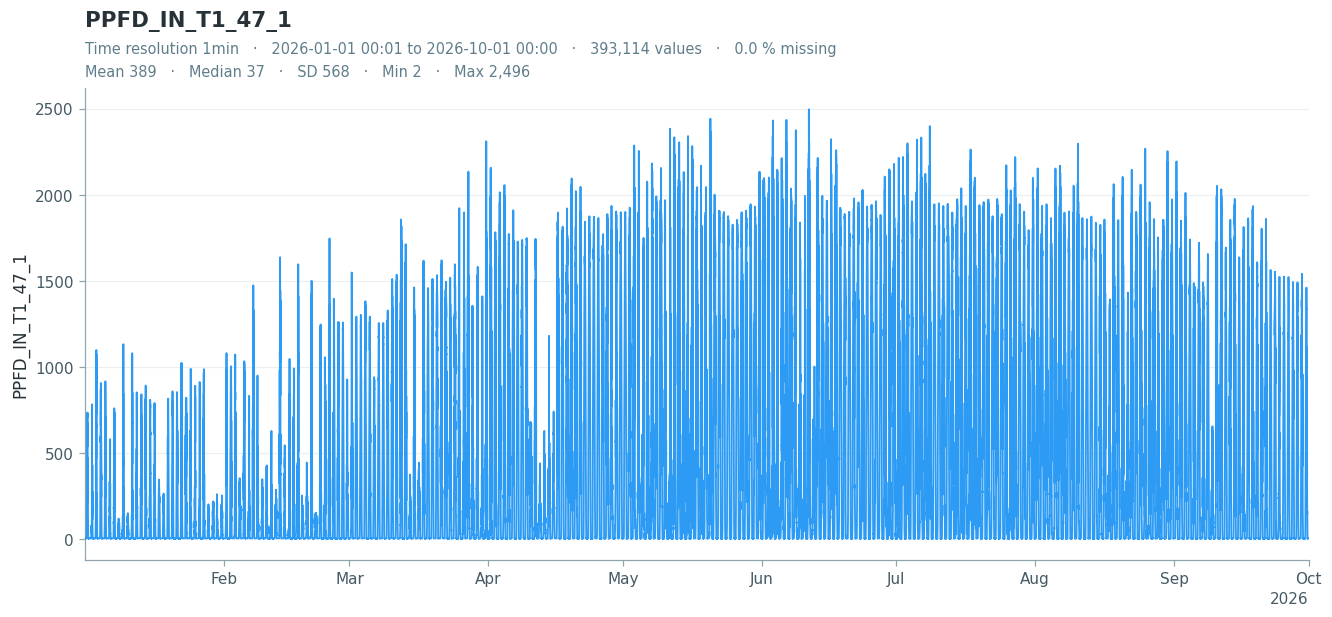

In [11]:
for varname, frame in data_detailed.items():
    dv.plotting.TimeSeries(series=frame[varname]).plot()

<br><br>

## ▶️ Start MeteoScreening with `diive`
Variables with too few records to screen are removed from `FIELDS` with a warning, and the others continue. `showplot_orig()` shows the raw series.

> Validating data for variable PPFD_IN_T1_47_1 ...

> Time resolutions used: 1min (393114 records)

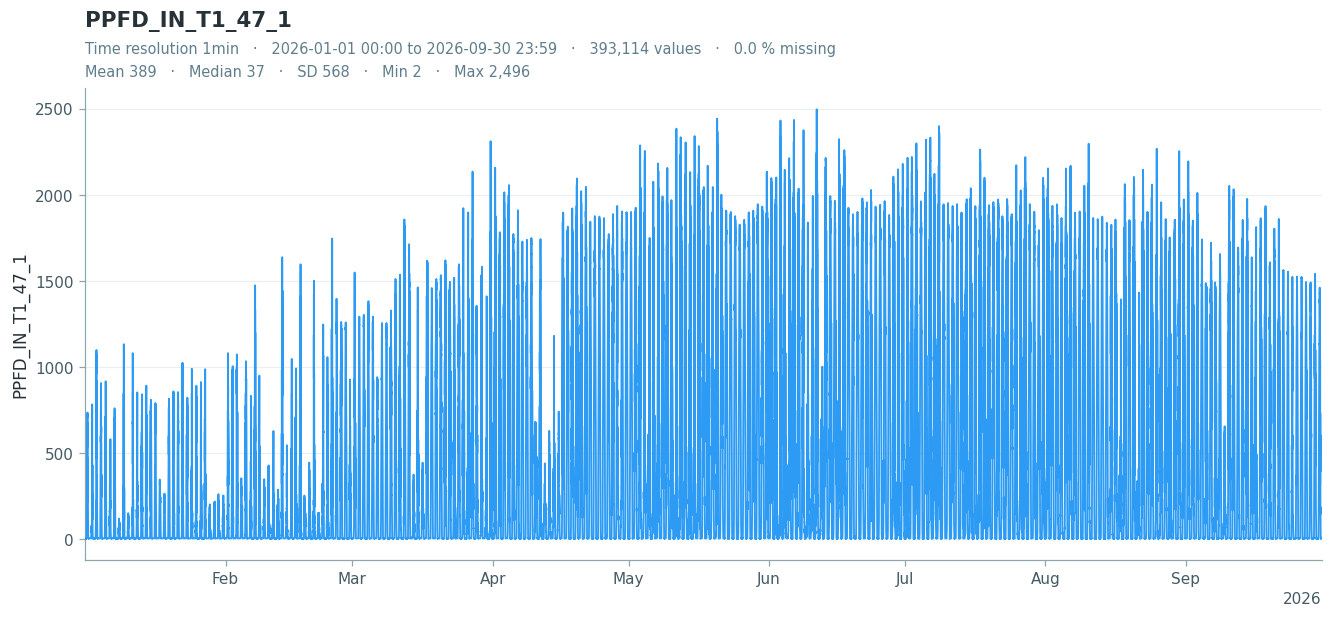

In [12]:
requested = list(FIELDS)
mscr = dv.qaqc.StepwiseMeteoScreeningDb(
    site=SITE,
    data_detailed=data_detailed,
    fields=requested,
    site_lat=SITE_LAT,
    site_lon=SITE_LON,
    utc_offset=TIMEZONE_OFFSET_TO_UTC_HOURS,
)
dropped = [v for v in requested if v not in mscr.fields]
if dropped:
    print(f'Too few records to screen, removed from FIELDS: {dropped}')
    FIELDS = list(mscr.fields)
    DOWNLOAD_SETTINGS['fields'] = [v for v in DOWNLOAD_SETTINGS['fields'] if v not in dropped]
# The settings this screening was built with, checked by the upload cell
SCREENED_SETTINGS = dict(DOWNLOAD_SETTINGS, site=mscr.site, fields=list(mscr.fields), offset=mscr.utc_offset)
mscr.showplot_orig()

<div class="alert alert-block alert-info">
    <b>No obvious outliers in the plot above?</b> Then outlier detection is not needed. Skip it and continue at:
    <ul>
        <li><b>🔧 Corrections</b> if the data need corrections,</li>
        <li><b>📈 Analyses</b> if they need no corrections but you want to run an analysis,</li>
        <li><b>🔁 Resampling</b> if they need neither.</li>
    </ul>
</div>

<br><br>

## 🔍 Outlier detection
Each method has a test cell and an `mscr.addflag()` cell. Rerun a test with other settings as often as needed: `mscr.addflag()` commits the latest run. Run only the methods your variable needs.

**Day and night.** With `separate_day_night=True` the statistic is computed separately for daytime and nighttime, split by the site coordinates. Some methods also take separate daytime and nighttime thresholds, see the docs.

**Windows.** Window sizes are time spans such as `'7D'` or record counts. A time span becomes a record count at the time resolution of the data, so one setting works for 1-minute and 10-minute data. The window counts the records present, so across gaps it covers more calendar days. Local SD with `separate_day_night=True` counts only daytime or only nighttime records, so its window covers even more days: at 47° N in January about 16-20 days for daytime and 10-13 days for nighttime with `'7D'`. Data that change resolution are tested per resolution period.

All tests are commented out, so *Run All* applies none. The example settings are only a starting point and can remove valid data. To use a test, check its settings and notes, uncomment the test and its `mscr.addflag()` cell, then check the preview.

In [ ]:
mscr.start_outlier_detection()

Plot the cleaned data at any point. With `interactive=True` the plot opens in the browser (Bokeh, with hover and zoom). `showplot_orig()` and `showplot_cleaned()` take the same argument.

In [ ]:
mscr.showplot_outlier_detection_cleaned()

### Manual removal
Flags single timestamps or `[start, end]` ranges (both ends included), e.g. known sensor failures. Use timestamps as in the downloaded data: local time, end of the averaging interval.
Docs: [flag_manualremoval_test](https://diive.readthedocs.io/en/latest/api/qaqc.html#diive.qaqc.StepwiseMeteoScreeningDb.flag_manualremoval_test), [ManualRemoval](https://diive.readthedocs.io/en/latest/api/outliers.html#diive.outliers.ManualRemoval).

In [ ]:
# REMOVE_DATES = [
#     # '2026-03-10 14:31:00',  # single record
#     # ['2026-03-12 08:00:00', '2026-03-12 11:30:00'],  # range, both ends included
# ]
# mscr.flag_manualremoval_test(remove_dates=REMOVE_DATES, showplot=True, verbose=True)

In [ ]:
# mscr.addflag()

### Hampel filter
Flags spikes far from the median of a sliding window, measured in median absolute deviations (MAD).

With `use_differencing=True` a single spike also removes both its neighbours at `n_sigma` 5.5. With `repeat=True` blocks of up to four bad values in a row are removed, also next to gaps and at the ends of the data. Of longer blocks only the outer values are removed. With `separate_day_night=True` daytime records are compared with the daytime records of the window, nighttime records with the nighttime ones. Records with up to 20 W m-2 potential radiation count as night, so twilight records are judged against the night statistics and can be removed. A sensor stuck at one value is not flagged, because the MAD is zero there. Use manual removal or *Set exact values to missing* for that.
Docs: [flag_outliers_hampel_test](https://diive.readthedocs.io/en/latest/api/qaqc.html#diive.qaqc.StepwiseMeteoScreeningDb.flag_outliers_hampel_test), [Hampel](https://diive.readthedocs.io/en/latest/api/outliers.html#diive.outliers.Hampel).

In [ ]:
# mscr.flag_outliers_hampel_test(
#     window_length='7D',  # converted to a record count, see above
#     n_sigma_daytime=5.5, n_sigma_nighttime=5.5,
#     use_differencing=True, separate_day_night=True,
#     repeat=True, showplot=True, verbose=True,
# )

In [ ]:
# mscr.addflag()

### Z-score
Flags values more than `thres_zscore` standard deviations from the mean of the whole period.

Not for precipitation: most records are zero, so every rain record looks like an outlier. Not for radiation with `separate_day_night=True`: twilight records count as night and stand out against the zeros.
Docs: [flag_outliers_zscore_test](https://diive.readthedocs.io/en/latest/api/qaqc.html#diive.qaqc.StepwiseMeteoScreeningDb.flag_outliers_zscore_test), [zScore](https://diive.readthedocs.io/en/latest/api/outliers.html#diive.outliers.zScore).

In [ ]:
# mscr.flag_outliers_zscore_test(
#     thres_zscore=4.5, separate_day_night=True,
#     repeat=True, showplot=True, verbose=True,
# )

In [ ]:
# mscr.addflag()

### Z-score (rolling window)
Z-score in a moving window of length `winsize`: it follows slow changes and flags local spikes.

Not for precipitation, as for the z-score: rain records stand out against the zeros.
Docs: [flag_outliers_zscore_rolling_test](https://diive.readthedocs.io/en/latest/api/qaqc.html#diive.qaqc.StepwiseMeteoScreeningDb.flag_outliers_zscore_rolling_test), [zScoreRolling](https://diive.readthedocs.io/en/latest/api/outliers.html#diive.outliers.zScoreRolling).

In [ ]:
# mscr.flag_outliers_zscore_rolling_test(
#     thres_zscore=3.5, winsize='13D',  # converted to a record count, see above
#     repeat=True, showplot=True, verbose=True,
# )

In [ ]:
# mscr.addflag()

### Local standard deviation
Flags values more than `n_sd` standard deviations from the rolling median over `winsize`.

Not for precipitation: the rolling median is zero most of the time, so rain records are removed.
Docs: [flag_outliers_localsd_test](https://diive.readthedocs.io/en/latest/api/qaqc.html#diive.qaqc.StepwiseMeteoScreeningDb.flag_outliers_localsd_test), [LocalSD](https://diive.readthedocs.io/en/latest/api/outliers.html#diive.outliers.LocalSD).

In [ ]:
# mscr.flag_outliers_localsd_test(
#     separate_day_night=True, n_sd=5.5, winsize='7D',  # record count, see above; day/night covers more days
#     constant_sd=False, repeat=False, showplot=True, verbose=True,
# )

In [ ]:
# mscr.addflag()

### Increments z-score
Flags records with unusually large jumps to their neighbours, from the z-score of the differences between records. Records are not compared across gaps.

Jumps are judged against the typical jump of the whole period, so variables with sudden real changes (precipitation, radiation under broken clouds) can lose valid records. Check the preview.
Docs: [flag_outliers_increments_zcore_test](https://diive.readthedocs.io/en/latest/api/qaqc.html#diive.qaqc.StepwiseMeteoScreeningDb.flag_outliers_increments_zcore_test), [zScoreIncrements](https://diive.readthedocs.io/en/latest/api/outliers.html#diive.outliers.zScoreIncrements).

In [ ]:
# mscr.flag_outliers_increments_zcore_test(thres_zscore=40, repeat=True, showplot=True, verbose=True)

In [ ]:
# mscr.addflag()

### Local outlier factor
Flags points that sit apart from their nearest neighbours. It always flags the `contamination` fraction of records, also in clean data, and is slow on high-res data.

Not for precipitation: rain records sit apart from the many zeros, so they are removed.
Docs: [flag_outliers_lof_test](https://diive.readthedocs.io/en/latest/api/qaqc.html#diive.qaqc.StepwiseMeteoScreeningDb.flag_outliers_lof_test), [LocalOutlierFactor](https://diive.readthedocs.io/en/latest/api/outliers.html#diive.outliers.LocalOutlierFactor).

In [ ]:
# mscr.flag_outliers_lof_test(
#     n_neighbors=30, contamination=0.01, separate_day_night=False,
#     repeat=False, n_jobs=-1, showplot=True, verbose=True,
# )

In [ ]:
# mscr.addflag()

### Absolute limits
Flags values outside `[minval, maxval]`, optionally with separate daytime and nighttime limits. The example limits fit air temperature in °C only.
Docs: [flag_outliers_abslim_test](https://diive.readthedocs.io/en/latest/api/qaqc.html#diive.qaqc.StepwiseMeteoScreeningDb.flag_outliers_abslim_test), [AbsoluteLimits](https://diive.readthedocs.io/en/latest/api/outliers.html#diive.outliers.AbsoluteLimits).

In [ ]:
mscr.flag_outliers_abslim_test(minval=20, maxval=999, showplot=True, verbose=True)

In [ ]:
mscr.addflag()

### Trim low
Flags values below `lower_limit` in the chosen period, plus the same number of the highest values. Set `lower_limit` for your variable and season: the example value 10 would remove most nighttime air temperatures of a cool month. Check the preview.
Docs: [flag_outliers_trim_low_test](https://diive.readthedocs.io/en/latest/api/qaqc.html#diive.qaqc.StepwiseMeteoScreeningDb.flag_outliers_trim_low_test), [TrimLow](https://diive.readthedocs.io/en/latest/api/outliers.html#diive.outliers.TrimLow).

In [ ]:
# mscr.flag_outliers_trim_low_test(
#     trim_daytime=False, trim_nighttime=True, lower_limit=10,
#     showplot=True, verbose=True,
# )

In [ ]:
# mscr.addflag()

### Missing values
Not an outlier test. Flags missing records so that `QCF` counts them. Needs no `addflag()`.
Docs: [flag_missingvals_test](https://diive.readthedocs.io/en/latest/api/qaqc.html#diive.qaqc.StepwiseMeteoScreeningDb.flag_missingvals_test).

In [ ]:
mscr.flag_missingvals_test(verbose=True)

### Overall quality flag QCF
Combines all committed flags into `QCF` and filters the series. Here every test gives 0 (good) or 2 (bad), and finalize removes the records flagged 2. Run it before resampling: without it, `resample()` ignores the committed flags. It also works when no test was committed.
Docs: [finalize_outlier_detection](https://diive.readthedocs.io/en/latest/api/qaqc.html#diive.qaqc.StepwiseMeteoScreeningDb.finalize_outlier_detection).

In [ ]:
mscr.finalize_outlier_detection()

#### Reports
How the QCF changes test by test, the counts of each test, and a summary of records and QCF.

In [ ]:
mscr.report_outlier_detection_qcf_evolution()

In [ ]:
mscr.report_outlier_detection_qcf_flags()

In [ ]:
mscr.report_outlier_detection_qcf_series()

#### Plots

In [ ]:
mscr.showplot_outlier_detection_qcf_heatmaps()
# mscr.showplot_outlier_detection_qcf_timeseries()

<br><br>

## 🔧 Corrections
Applied to the high-res data, filtered by `QCF` if outlier detection ran. Run only what applies to your variable.

All calls are commented out, because they change the data with example settings. Edit the settings, then uncomment the call.

In [ ]:
mscr.showplot_cleaned()

### Remove radiation zero offset
For shortwave radiation and PAR, which read below zero at night. The correction runs in this order:
1. **Night:** records with potential radiation below 0.001 W m-2.
2. **Daily offset:** the mean of the night values of each calendar day, i.e. the night before sunrise and the night after sunset of that date. All records of the day get this one value, there is no interpolation between days. Days without night values get the median offset of all days.
3. **Subtract:** the offset is subtracted from every record of the day, day and night.
4. **Night to 0:** night records are set to 0.
5. **Clamp:** values still below 0, e.g. daytime records at dawn and dusk, are set to 0. `clamp_negatives=False` keeps them.

The figure shows these steps with their counts, the daily offset, the diel cycle near zero after steps 3 and 5, the night values before and after subtracting the offset, and a summary.
Docs: [correction_remove_nighttime_zero_offset](https://diive.readthedocs.io/en/latest/api/qaqc.html#diive.qaqc.StepwiseMeteoScreeningDb.correction_remove_nighttime_zero_offset).

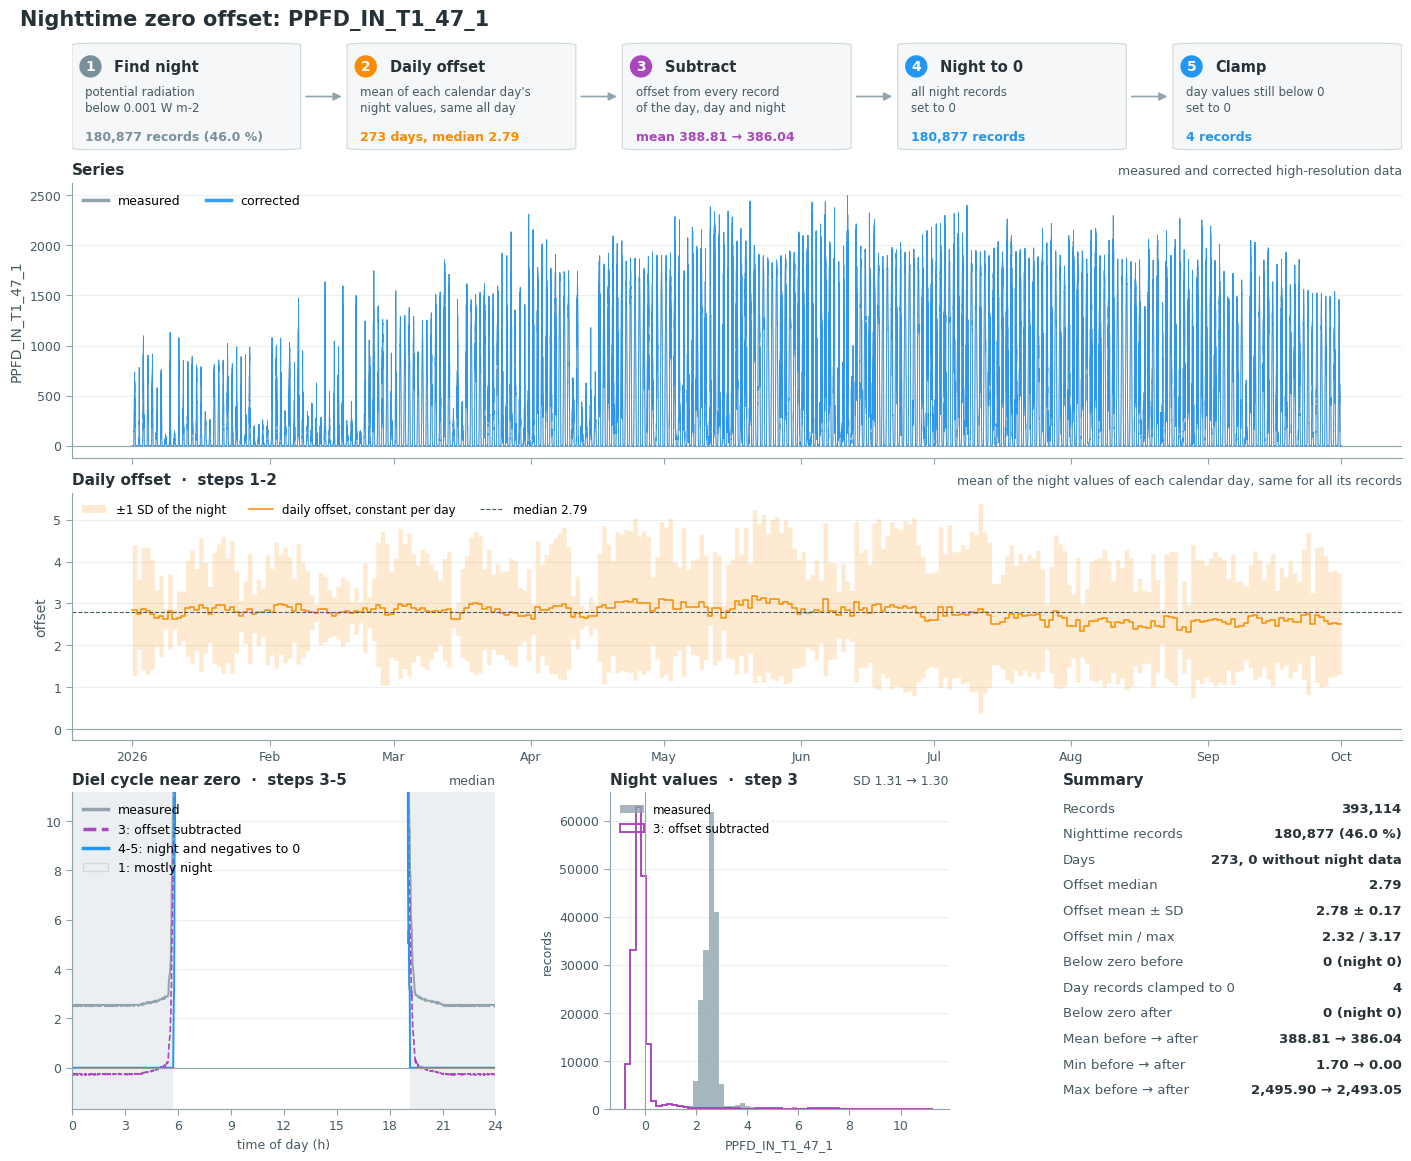

In [13]:
mscr.correction_remove_nighttime_zero_offset()

### Remove relative humidity offset
For relative humidity that reads above 100 %. The correction runs in this order:
1. **Find > 100 %:** the values above 100 %.
2. **Daily offset:** for each day with such values, their mean minus 100. All records of the day get this one value.
3. **Other days:** the offset is interpolated linearly, record by record, between the nearest days with values above 100 %, and carried before the first and after the last such day. Without any value above 100 % the offset is 0.
4. **Subtract:** the offset is subtracted from every record.
5. **Cap at 100 %:** values still above 100 % are set to 100 %.

A single day above 100 % lowers every record of the period, so the result depends on the period screened. The figure shows these steps with their counts, the offset, the values near 100 %, the daily maximum and a summary. A pile just below 100 % without values above it means the sensor or logger caps the readings, and the correction finds no offset.
Docs: [correction_remove_relativehumidity_offset](https://diive.readthedocs.io/en/latest/api/qaqc.html#diive.qaqc.StepwiseMeteoScreeningDb.correction_remove_relativehumidity_offset).

In [ ]:
# mscr.correction_remove_relativehumidity_offset()

### Set to maximum or minimum threshold
Sets values above or below a threshold to the threshold. The result looks plausible but was not measured, so removing the value is usually better.
Docs: [correction_setto_max_threshold](https://diive.readthedocs.io/en/latest/api/qaqc.html#diive.qaqc.StepwiseMeteoScreeningDb.correction_setto_max_threshold), [correction_setto_min_threshold](https://diive.readthedocs.io/en/latest/api/qaqc.html#diive.qaqc.StepwiseMeteoScreeningDb.correction_setto_min_threshold).

In [ ]:
# mscr.correction_setto_max_threshold(threshold=30)
# mscr.correction_setto_min_threshold(threshold=-5)

### Set a time range to a value
Sets all records at the given dates or in the given ranges (both ends included) to one value.
Docs: [correction_setto_value](https://diive.readthedocs.io/en/latest/api/qaqc.html#diive.qaqc.StepwiseMeteoScreeningDb.correction_setto_value).

In [ ]:
# DATES = [
#     # '2026-03-10 14:30:00',  # single record
#     ['2026-03-12 08:00:00', '2026-03-12 11:30:00'],  # range, both ends included
# ]
# mscr.correction_setto_value(dates=DATES, value=3.7, verbose=1)
# mscr.showplot_cleaned(interactive=False)

### Set exact values to missing
Sets records equal to the given values to missing, e.g. a stuck reading. The first cell lists the most frequent values and changes nothing.
Docs: [correction_set_exact_value_to_missing](https://diive.readthedocs.io/en/latest/api/qaqc.html#diive.qaqc.StepwiseMeteoScreeningDb.correction_set_exact_value_to_missing).

In [ ]:
# for ff in mscr.fields:
#     vc = mscr.series_hires_cleaned[ff].value_counts()
#     print(f'--- {ff} (top 20 of {mscr.series_hires_cleaned[ff].count()} records) ---')
#     print(vc.head(20))

In [ ]:
# mscr.correction_set_exact_value_to_missing(values=[0])
# mscr.showplot_cleaned(interactive=False)

<br><br>

## 📈 Analyses (optional)

### Check for timestamp shifts
For radiation variables. Correlates the measured series with potential radiation day by day. A steady offset points to a shifted timestamp.
Docs: [analysis_potential_radiation_correlation](https://diive.readthedocs.io/en/latest/api/qaqc.html#diive.qaqc.StepwiseMeteoScreeningDb.analysis_potential_radiation_correlation).

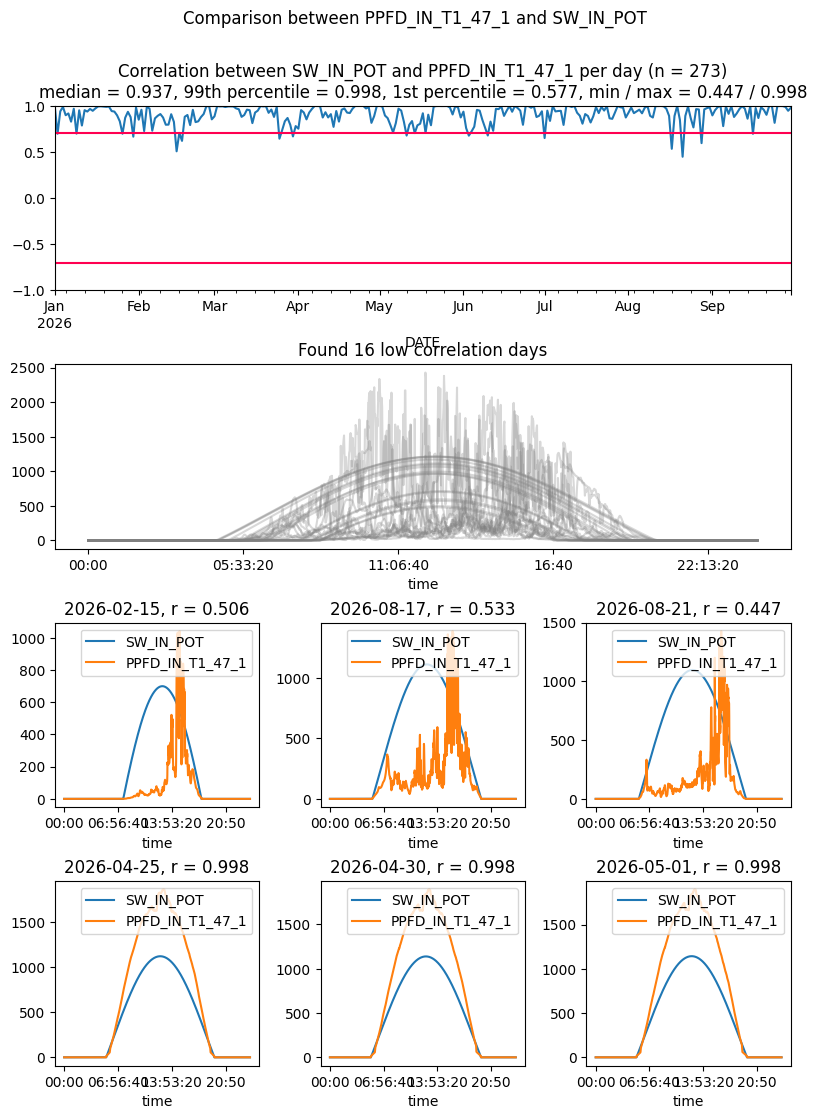

In [14]:
_ = mscr.analysis_potential_radiation_correlation(
    utc_offset=TIMEZONE_OFFSET_TO_UTC_HOURS, mincorr=0.7, showplot=True)

<br><br>

## 🔁 Resampling

### Resample
Resamples the screened high-res series to `RESAMPLING_FREQ`, with `TIMESTAMP_END` timestamps ready for upload.

`mincounts_perc` sets how much of each target period the kept records must fill. Periods with less are missing.
- `'mean'`: the share becomes a minimum number of records, rounded down. Below three, one record is enough, so 10-minute data resampled to 30 minutes need one record per half-hour.
- `'sum'`: the kept records must cover that share of the period. For precipitation use `1` if partial sums are not wanted: a sum over a partly covered period is too low.

`'mean'` is an arithmetic mean and does not suit angles such as wind direction, which need a circular mean. This notebook does not compute one.

After changing the screened data, run this cell again, or the upload stops with an error.
Docs: [resample](https://diive.readthedocs.io/en/latest/api/qaqc.html#diive.qaqc.StepwiseMeteoScreeningDb.resample).

> Resampling PPFD_IN_T1_47_1 from min to 30min (mean) ...

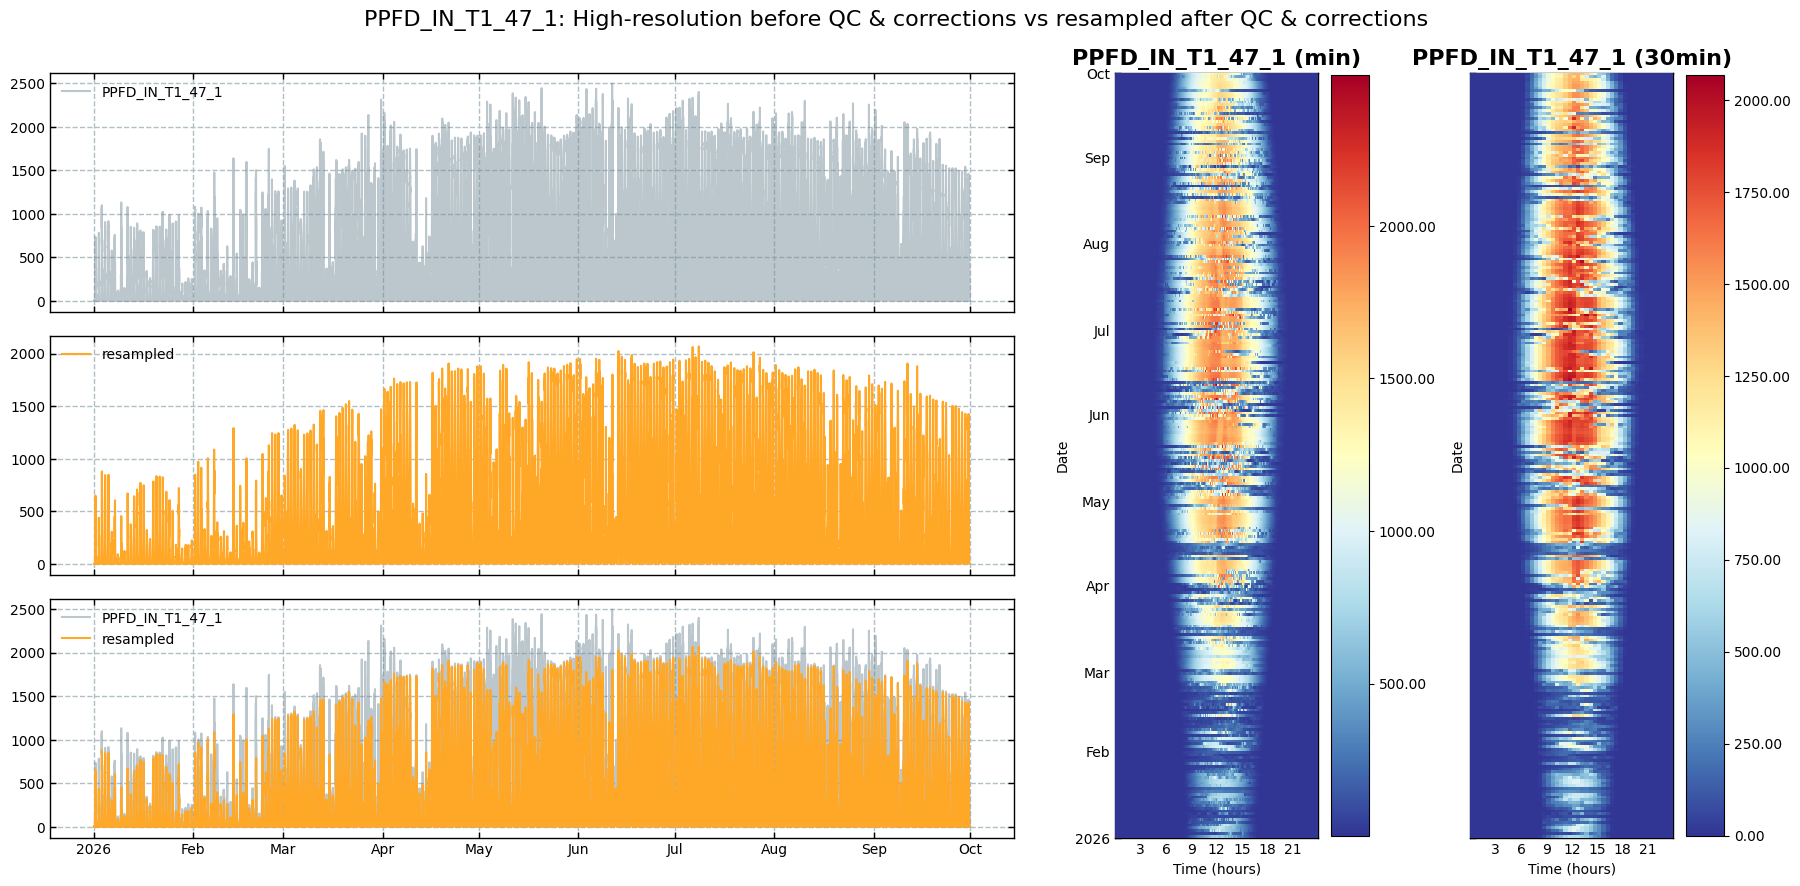

In [15]:
mscr.resample(to_freqstr=RESAMPLING_FREQ, agg=RESAMPLING_AGG, mincounts_perc=.5)
mscr.showplot_resampled()

### Check the resampled time resolution

In [16]:
def duration(freq):
    # As durations, so '24h' equals '1D'
    return pd.Timedelta(to_offset(freq).nanos, unit='ns')


def as_text(td):
    return f'{td / pd.Timedelta("1h"):g} h' if td >= pd.Timedelta('1h') else f'{td / pd.Timedelta("1min"):g} min'


for v in mscr.resampled_detailed.keys():
    freq = mscr.tags[v]['freq']  # set by resample()
    status = 'PASSED' if duration(freq) == duration(RESAMPLING_FREQ) else '(!) FAILED'
    print(f'{status} - {v}: resampled to {as_text(duration(freq))}, '
          f'RESAMPLING_FREQ {as_text(duration(RESAMPLING_FREQ))}')

PASSED - PPFD_IN_T1_47_1: resampled to 30 min, RESAMPLING_FREQ 30 min


<br><br>

## ⬆️ Upload data to database

**Existing screened data are overwritten.** The upload writes to the processed bucket as data version `meteoscreening_diive`. With `delete_from_db_before_upload=True` it first deletes the stored values of each uploaded variable (same site, measurement, name and data version) between `START` and `STOP`, both included, then writes the new ones. Old values are removed also where the new data have no records, e.g. at the end of the period. Raw data, other variables and other data versions stay untouched.

The upload runs only with `UPLOAD = True`. It stops before deleting anything if:
- `SITE`, `MEASUREMENT`, `FIELDS`, `START`, `STOP` or `TIMEZONE_OFFSET_TO_UTC_HOURS` differ from the values used for the download or the screening (`mscr`), e.g. after a new download without a new screening. The stored values would be shifted, or a neighbouring period deleted. Run the notebook again from *Download*.
- a variable was resampled to a resolution other than `RESAMPLING_FREQ`, e.g. after an extra `resample()` call. Run *Resample* again.

In [17]:
upload_attempted = False  # read by the verify cells
if not UPLOAD:
    print('UPLOAD = False: nothing was uploaded. Set UPLOAD = True in the user settings to write the data.')
else:
    # Refuse before anything is deleted if the settings changed after the download or the screening:
    # a changed offset stores shifted values, a changed START or STOP deletes a neighbouring period,
    # and a download run again without a new screening would upload the old screening in its range.
    now = dict(site=SITE, measurement=MEASUREMENT, fields=list(FIELDS), start=START, stop=STOP,
               offset=TIMEZONE_OFFSET_TO_UTC_HOURS)
    used = {'download': DOWNLOAD_SETTINGS, 'screening': SCREENED_SETTINGS,
            'screening object': dict(site=mscr.site, fields=list(mscr.fields), offset=mscr.utc_offset),
            'resampled data': dict(fields=list(mscr.resampled_detailed.keys()))}

    def as_compared(k, v):
        return pd.Timestamp(v) if k in ('start', 'stop') else sorted(v) if k == 'fields' else v

    changed = {f'{k} ({name})': (s[k], now[k]) for name, s in used.items() for k in s
               if as_compared(k, s[k]) != as_compared(k, now[k])}
    if changed:
        raise RuntimeError(
            f'Nothing uploaded. Settings differ (used, now): {changed}. '
            f'Run the notebook again from the download.')
    # Refuse before anything is deleted: the stored values between START and STOP would be
    # replaced by data at another resolution. Compared as durations, so '24h' equals '1D'.
    target = pd.Timedelta(to_offset(RESAMPLING_FREQ).nanos, unit='ns')
    wrong_freq = {v: mscr.tags[v]['freq'] for v in mscr.resampled_detailed.keys()
                  if pd.Timedelta(to_offset(mscr.tags[v]['freq']).nanos, unit='ns') != target}
    if wrong_freq:
        raise RuntimeError(
            f'Nothing uploaded. Resampled to a resolution other than RESAMPLING_FREQ '
            f'({RESAMPLING_FREQ!r}): {wrong_freq}. Run the Resample cell again with RESAMPLING_FREQ.')
    print(f'Uploading to bucket {BUCKET_PROCESSED}')
    upload_attempted = True  # set before the writes, so the verify cells also report a failed write
    for v in mscr.resampled_detailed.keys():
        dbc.upload_singlevar(
            to_bucket=BUCKET_PROCESSED,
            to_measurement=assigned_measurements[v],
            var_df=mscr.resampled_detailed[v],
            timezone_offset_to_utc_hours=TIMEZONE_OFFSET_TO_UTC_HOURS,
            delete_from_db_before_upload=True,
            delete_start=START,
            delete_stop=STOP,
        )

Uploading to bucket ch-lae_processed


> Deleted variables ['PPFD_IN_T1_47_1'] for site CH-LAE between 2026-01-01T00:00:01+01:00 and 
2026-10-01T00:00:01+01:00 from measurements ['PPFD'] in bucket ch-lae_processed.

> Connecting to database ...

> --> UPLOAD TO DATABASE BUCKET ch-lae_processed:  ['PPFD_IN_T1_47_1']

v Upload finished: 13104 points of PPFD_IN_T1_47_1 written to bucket ch-lae_processed.

### Verify upload
Downloads the uploaded data again with `DOWNLOAD_SETTINGS`, over the range the upload deleted (`START` to `STOP`, both included), and compares them with the resampled data: same timestamps (local `TIMESTAMP_END`), same values, same number of records. A variable with every record rejected had nothing to write, and the check says so. Otherwise a variable missing from the download means the write failed. Both cells do nothing if nothing was uploaded.

In [18]:
if not upload_attempted:
    print('Nothing was uploaded, so there is nothing to verify.')
else:
    # Fresh names so the screened originals are not overwritten. The download excludes its stop,
    # so one second more reads the same range the upload deleted, STOP included.
    check_simple, check_detailed, check_measurements = dbc.download(
        bucket=BUCKET_PROCESSED,
        measurements=[DOWNLOAD_SETTINGS['measurement']],
        fields=DOWNLOAD_SETTINGS['fields'],
        start=DOWNLOAD_SETTINGS['start'],
        stop=str(pd.Timestamp(DOWNLOAD_SETTINGS['stop']) + pd.Timedelta(seconds=1)),
        timezone_offset_to_utc_hours=DOWNLOAD_SETTINGS['offset'],
        data_version='meteoscreening_diive',
    )
    display(check_simple)

> DOWNLOADING from bucket ch-lae_processed: variables ['PPFD_IN_T1_47_1'] from measurements 
['PPFD'], data version ['meteoscreening_diive'], between 2026-01-01 00:00:01 and 2026-10-01 00:00:02
(timezone offset to UTC 1)

> Downloaded data for 1 variables:

> <-- PPFD_IN_T1_47_1: 13,104 records from 2026-01-01 00:30:00 to 2026-10-01 00:00:00, time 
resolution 30min (freq tag: 30min)

,PPFD_IN_T1_47_1
TIMESTAMP_END,
2026-01-01 00:30:00,0.0
2026-01-01 01:00:00,0.0
2026-01-01 01:30:00,0.0
2026-01-01 02:00:00,0.0
2026-01-01 02:30:00,0.0
...,...
2026-09-30 22:00:00,0.0
2026-09-30 22:30:00,0.0
2026-09-30 23:00:00,0.0


In [19]:
if not upload_attempted:
    print('Nothing was uploaded, so there is nothing to verify.')
else:
    for v in mscr.resampled_detailed.keys():
        uploaded_vals = mscr.resampled_detailed[v][v].dropna()  # NaN records are not written
        stored_vals = check_detailed[v][v].dropna() if v in check_detailed else uploaded_vals.iloc[:0]
        if uploaded_vals.empty:
            status = 'NOTHING UPLOADED' if stored_vals.empty else '(!) FAILED'
            print(f'{status} - {v}: every record was rejected, so there was nothing to write. '
                  f'{len(stored_vals)} values stored between START and STOP.')
            continue
        if v not in check_detailed:
            print(f'(!) FAILED - {v}: not in the database after upload')
            continue
        same_stamps = len(stored_vals) == len(uploaded_vals) and stored_vals.index.isin(uploaded_vals.index).all()
        diff_vals = (stored_vals - uploaded_vals.reindex(stored_vals.index)).abs()
        same_vals = same_stamps and (diff_vals <= 1e-9 * uploaded_vals.abs().clip(lower=1).reindex(stored_vals.index)).all()
        status = 'PASSED' if same_vals else '(!) FAILED'
        print(f'{status} - {v}: {len(stored_vals)} stored, {len(uploaded_vals)} uploaded, '
              f'same stamps: {same_stamps}, same values: {same_vals}')

PASSED - PPFD_IN_T1_47_1: 13104 stored, 13104 uploaded, same stamps: True, same values: True


<br><br>

## ✅ End of notebook

In [20]:
print(f"Finished: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

Finished: 2026-10-22 13:42:36
